# Tugas - Clustering dengan K-Means dan Hierarchical Clustering

| Nama | NRP |
|------|-----|
| Hilal Tsabitul Azmi Arba'i | 5054251008 |

## Deskripsi Tugas
Pada tugas ini, kalian akan membangun model clustering menggunakan K-Means dan Hierarchical Clustering untuk mengelompokkan posting Facebook penjual berdasarkan pola engagement-nya (like, komentar, share, dan reaksi emoji).

Dataset yang digunakan: `Live.csv` (Facebook Live Sellers in Thailand, UCI). Setiap baris adalah satu posting Facebook dari penjual fashion dan kosmetik di Thailand.

Tujuan utama dari tugas ini adalah memahami cara kerja algoritma clustering secara praktik, khususnya:
1. Penentuan jumlah cluster yang optimal (Elbow Method dan Silhouette Score) serta pengaruh transformasi log dan feature scaling pada K-Means
2. Perbedaan metode linkage dan pembacaan dendrogram pada Hierarchical Clustering
3. Perbandingan hasil K-Means dan Hierarchical Clustering

**Catatan:** Kolom `status_type` TIDAK boleh digunakan sebagai fitur clustering. Kolom ini hanya dipakai untuk membantu menafsirkan cluster pada tahap evaluasi.

Langkah-langkah yang harus dilakukan antara lain:
1. Persiapan Dataset dan Eksplorasi Awal
   - Memuat dataset, melihat struktur data, dan distribusi fitur.
2. Preprocessing
   - Memproses data agar siap digunakan dalam clustering.
3. Eksperimen K-Means
   - Tentukan jumlah cluster dengan Elbow Method dan Silhouette Score, lalu bangun model K-Means.
4. Eksperimen Hierarchical Clustering
   - Amati dendrogram, bandingkan variasi linkage, lalu bangun model Agglomerative Clustering.
5. Evaluasi Model
   - Hitung metrik evaluasi dan visualisasikan hasilnya.
6. Analisis
7. Kesimpulan dan Saran

# 1. Persiapan Dataset dan Eksplorasi Awal

In [1]:
# Import library yang dibutuhkan (pandas, numpy, matplotlib, seaborn, sklearn, scipy, dll)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.cluster import KMeans, AgglomerativeClustering
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score,
)
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from yellowbrick.cluster import KElbowVisualizer


In [2]:
# Load dataset dan tampilkan informasi dasar: jumlah baris dan kolom, tipe data, statistik deskriptif, jumlah missing value, dan jumlah baris duplikat.
# Perhatikan apakah ada kolom yang seluruhnya kosong.
df = pd.read_csv("Live.csv")
print("jumlah baris dan kolom", df.shape)
print("info data")
display(df.info())
print("deskripsi data")
display(df.describe())
print("data hilang", df.duplicated().sum())
print("missing value", df.isna().sum())


jumlah baris dan kolom (7050, 16)
info data
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7050 entries, 0 to 7049
Data columns (total 16 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   status_id         7050 non-null   int64  
 1   status_type       7050 non-null   object 
 2   status_published  7050 non-null   object 
 3   num_reactions     7050 non-null   int64  
 4   num_comments      7050 non-null   int64  
 5   num_shares        7050 non-null   int64  
 6   num_likes         7050 non-null   int64  
 7   num_loves         7050 non-null   int64  
 8   num_wows          7050 non-null   int64  
 9   num_hahas         7050 non-null   int64  
 10  num_sads          7050 non-null   int64  
 11  num_angrys        7050 non-null   int64  
 12  Column1           0 non-null      float64
 13  Column2           0 non-null      float64
 14  Column3           0 non-null      float64
 15  Column4           0 non-null      float64
dty

None

deskripsi data


,status_id,num_reactions,num_comments,num_shares,num_likes,num_loves,num_wows,num_hahas,num_sads,num_angrys,Column1,Column2,Column3,Column4
count,7050.000000,7050.000000,7050.000000,7050.000000,7050.000000,7050.000000,7050.000000,7050.000000,7050.000000,7050.000000,0.0,0.0,0.0,0.0
mean,3525.500000,230.117163,224.356028,40.022553,215.043121,12.728652,1.289362,0.696454,0.243688,0.113191,NaN,NaN,NaN,NaN
std,2035.304031,462.625309,889.636820,131.599965,449.472357,39.972930,8.719650,3.957183,1.597156,0.726812,NaN,NaN,NaN,NaN
min,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN
25%,1763.250000,17.000000,0.000000,0.000000,17.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN
50%,3525.500000,59.500000,4.000000,0.000000,58.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN
75%,5287.750000,219.000000,23.000000,4.000000,184.750000,3.000000,0.000000,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN
max,7050.000000,4710.000000,20990.000000,3424.000000,4710.000000,657.000000,278.000000,157.000000,51.000000,31.000000,NaN,NaN,NaN,NaN


data hilang 0
missing value status_id              0
status_type            0
status_published       0
num_reactions          0
num_comments           0
num_shares             0
num_likes              0
num_loves              0
num_wows               0
num_hahas              0
num_sads               0
num_angrys             0
Column1             7050
Column2             7050
Column3             7050
Column4             7050
dtype: int64


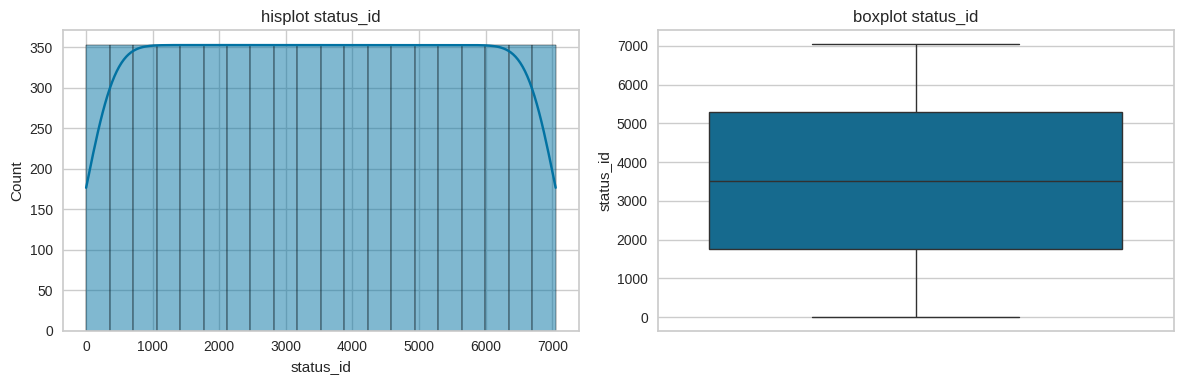

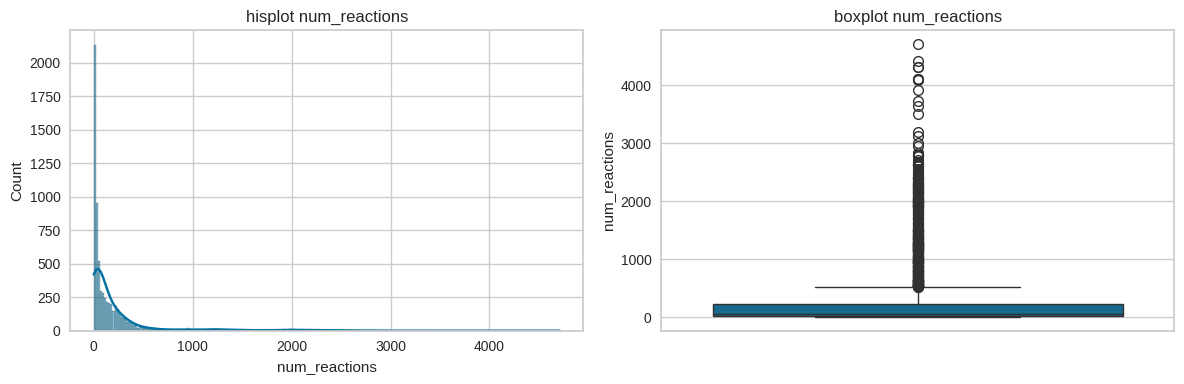

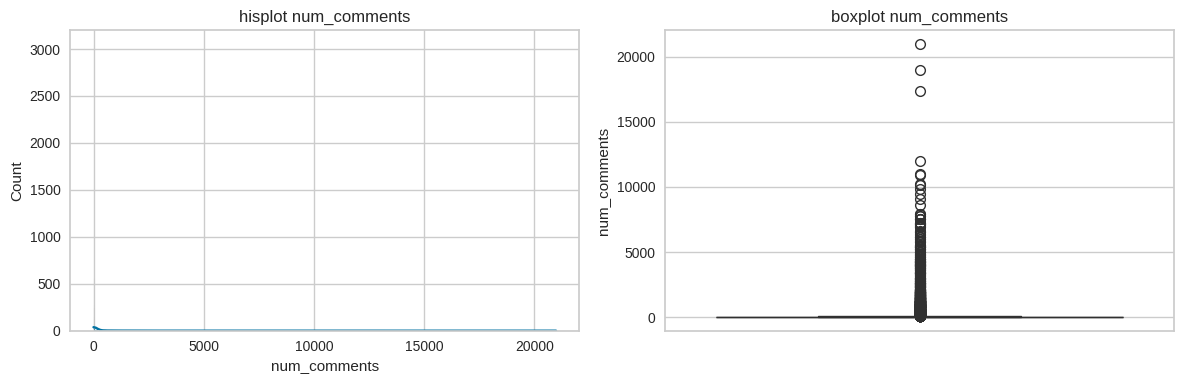

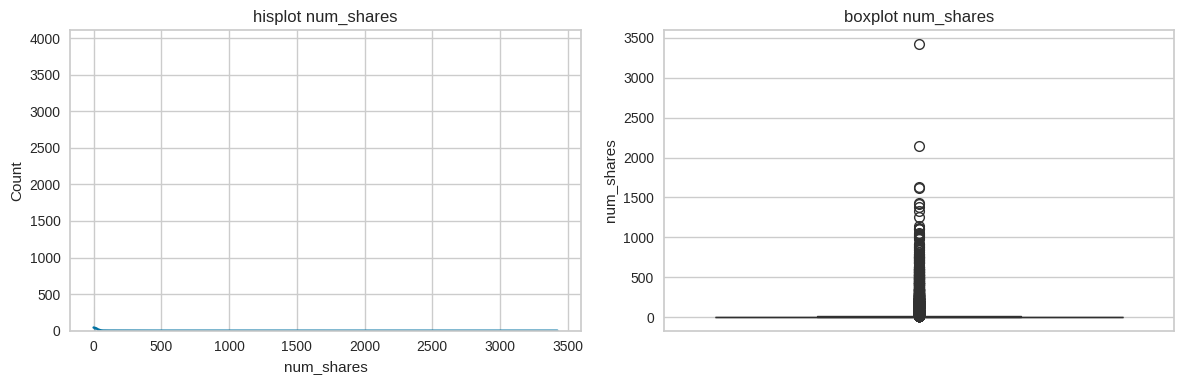

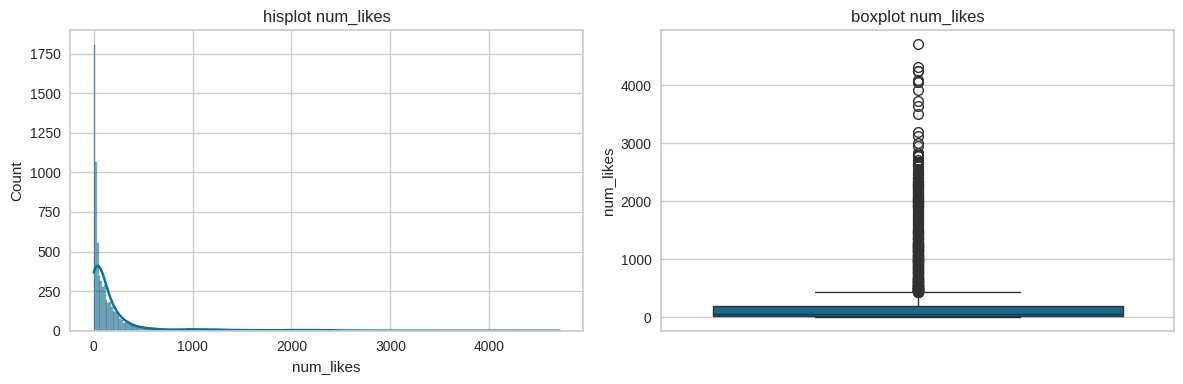

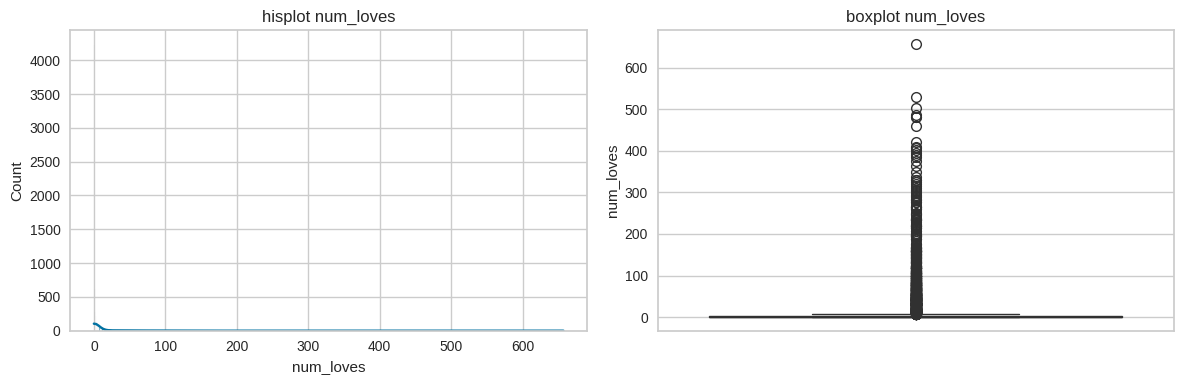

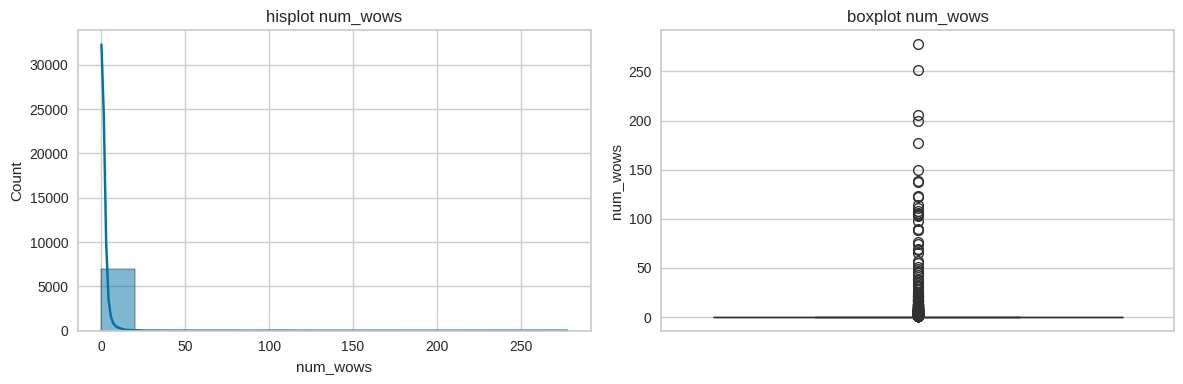

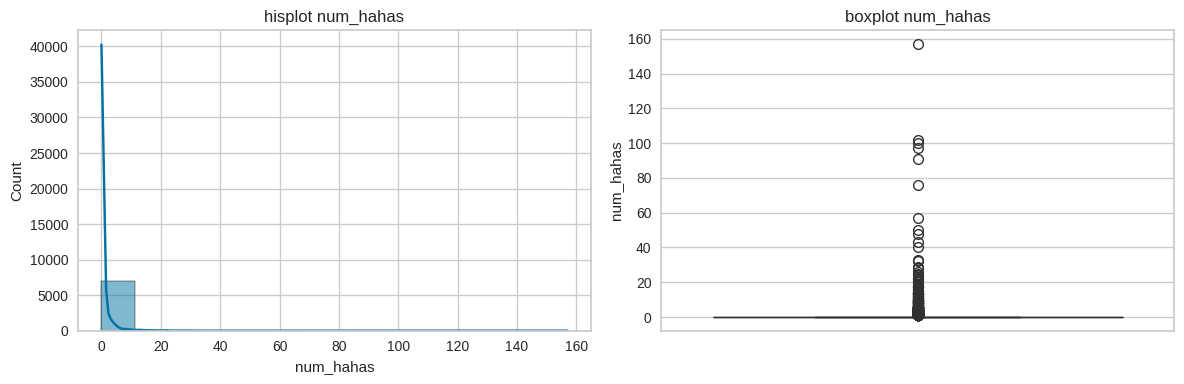

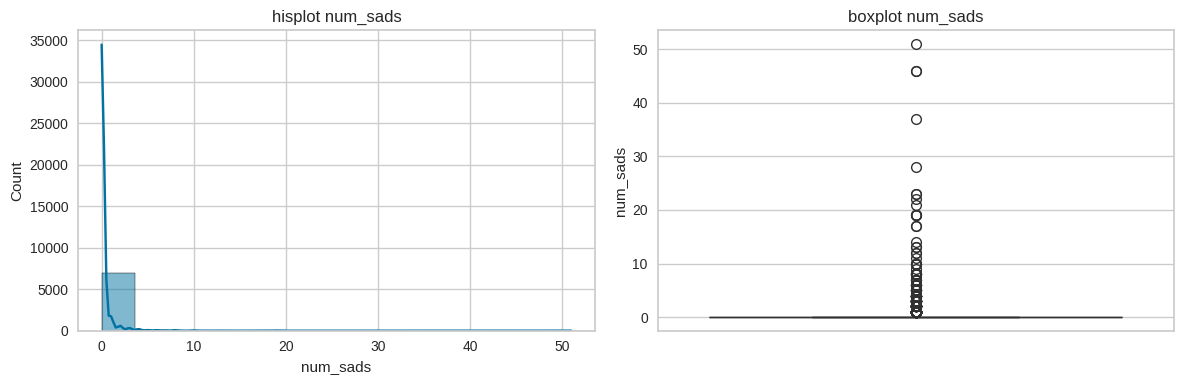

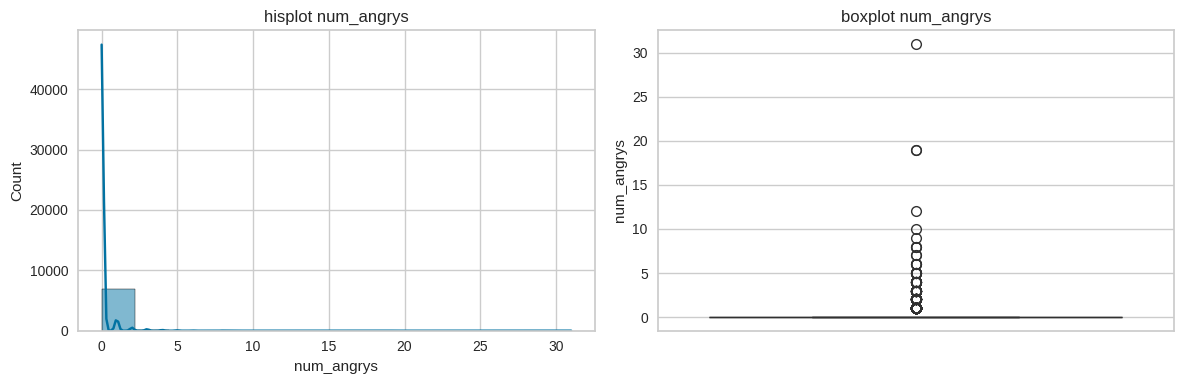

In [3]:
# Tampilkan distribusi fitur hitungan (histogram atau boxplot).
# Perhatikan skewness, proporsi nilai nol, dan perbedaan skala antar fitur (misalnya num_comments vs num_angrys), karena ini penting untuk tahap preprocessing.
df = df.drop(columns=["Column1", "Column2", "Column3", "Column4"])
num_col = df.select_dtypes(include=[np.number]).columns.tolist()
for xx in num_col:
    values = pd.to_numeric(df[xx], errors="coerce")
    values = values[np.isfinite(values)]
    
    fig, axes= plt.subplots(1, 2, figsize=(12,4))
    sns.histplot(data=df, x=values, kde=True, ax=axes[0])
    axes[0].set_title(f"hisplot {xx}")
    
    sns.boxplot(data=df, y=values, ax=axes[1])
    axes[1].set_title(f"boxplot {xx}")
    
    plt.tight_layout()
    plt.show()

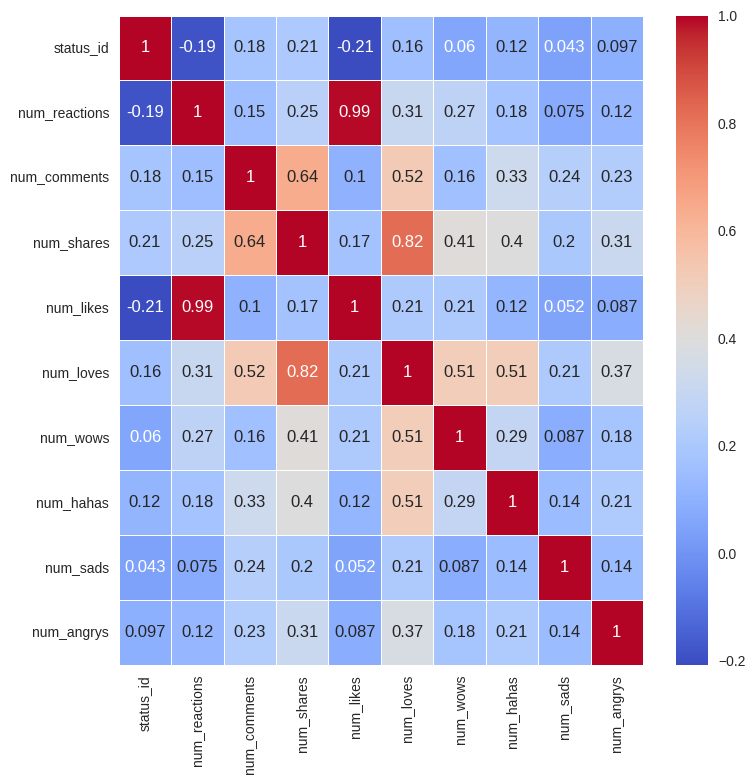

In [4]:
# Tampilkan heatmap korelasi antar fitur hitungan.
# Perhatikan fitur-fitur yang berkorelasi sangat tinggi atau saling berkaitan secara definisi (redundan), karena memengaruhi perhitungan jarak pada clustering.
plt.figure(figsize=(8,8))
sns.heatmap(df[num_col].corr(), annot=True, cmap="coolwarm", linewidths=0.5)
plt.tight_layout()
plt.show()

       jumlah_posting  jumlah_posting_emoji  proporsi_posting_emoji
tahun                                                              
2012              589                     0                  0.0000
2013              500                     0                  0.0000
2014              233                     0                  0.0000
2015              337                     0                  0.0000
2016              588                   400                  0.6803
2017             2253                  1221                  0.5419
2018             2550                  1473                  0.5776


,jumlah_posting,jumlah_posting_emoji,proporsi_posting_emoji
tahun,,,
2012,589,0,0.00%
2013,500,0,0.00%
2014,233,0,0.00%
2015,337,0,0.00%
2016,588,400,68.03%
2017,2253,1221,54.19%
2018,2550,1473,57.76%


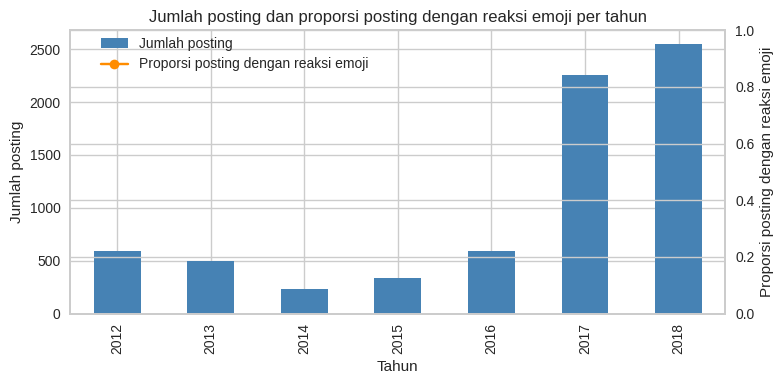

In [5]:
# Ubah kolom status_published menjadi datetime.
# Tampilkan jumlah posting dan proporsi posting yang memiliki reaksi emoji pada setiap tahun.
# Amati apakah ada perubahan pola dari tahun ke tahun.
df["status_published"] = pd.to_datetime(df["status_published"], errors="coerce")
df["tahun"] = df["status_published"].dt.year

emoji_cols = ["num_loves", "num_wows", "num_hahas", "num_sads", "num_angrys"]
df["punya_reaksi_emoji"] = (df[emoji_cols].sum(axis=1) > 0).astype(int)

ringkasan_tahun = df.groupby("tahun").agg(
    jumlah_posting=("status_id", "count"),
    jumlah_posting_emoji=("punya_reaksi_emoji", "sum"),
)
ringkasan_tahun["proporsi_posting_emoji"] = (
    ringkasan_tahun["jumlah_posting_emoji"] / ringkasan_tahun["jumlah_posting"]
)
print(ringkasan_tahun.round(4))
display(ringkasan_tahun.style.format({"proporsi_posting_emoji": "{:.2%}"}))

fig, ax1 = plt.subplots(figsize=(8, 4))
ringkasan_tahun["jumlah_posting"].plot(
    kind="bar", ax=ax1, color="steelblue", label="Jumlah posting"
)
ax1.set_xlabel("Tahun")
ax1.set_ylabel("Jumlah posting")
ax2 = ax1.twinx()
ringkasan_tahun["proporsi_posting_emoji"].plot(
    kind="line", ax=ax2, color="darkorange", marker="o",
    label="Proporsi posting dengan reaksi emoji",
)
ax2.set_ylabel("Proporsi posting dengan reaksi emoji")
ax2.set_ylim(0, 1)
ax1.set_title("Jumlah posting dan proporsi posting dengan reaksi emoji per tahun")
fig.legend(loc="upper left", bbox_to_anchor=(0.12, 0.92))
plt.tight_layout()
plt.show()


Median num_likes, num_comments, dan num_shares per status_type:


,num_likes,num_comments,num_shares
status_type,,,
photo,34.0,2.0,0.0
video,117.0,39.0,12.0
status,117.0,10.0,0.0
link,48.0,1.0,0.0


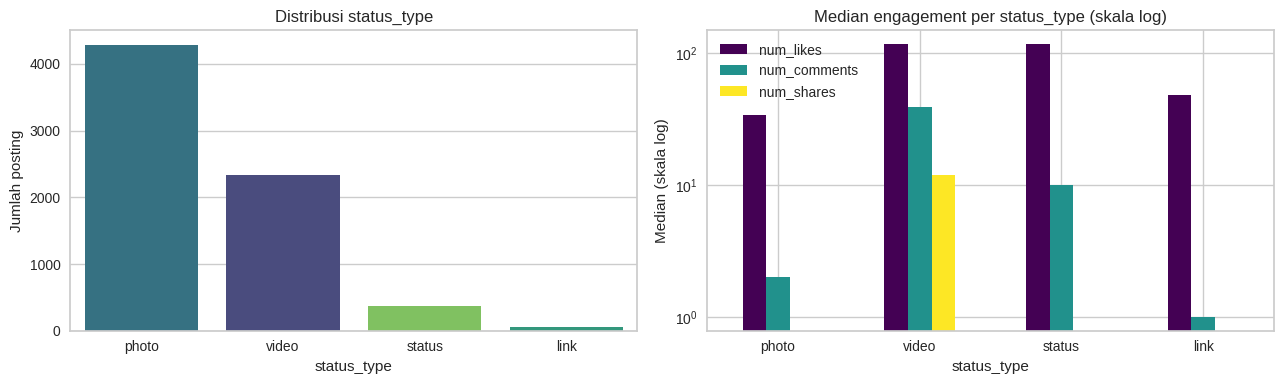

In [6]:
# Tampilkan distribusi status_type dalam bentuk bar plot.
# Bandingkan median num_likes, num_comments, dan num_shares untuk setiap status_type.
urutan_status = df["status_type"].value_counts().index

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.countplot(
    data=df, x="status_type", order=urutan_status, ax=axes[0],
    hue="status_type", legend=False, palette="viridis",
)
axes[0].set_title("Distribusi status_type")
axes[0].set_xlabel("status_type")
axes[0].set_ylabel("Jumlah posting")

median_status = (
    df.groupby("status_type")[["num_likes", "num_comments", "num_shares"]]
    .median()
    .reindex(urutan_status)
)
print("Median num_likes, num_comments, dan num_shares per status_type:")
display(median_status)

median_status.plot(kind="bar", ax=axes[1], logy=True, colormap="viridis")
axes[1].set_title("Median engagement per status_type (skala log)")
axes[1].set_xlabel("status_type")
axes[1].set_ylabel("Median (skala log)")
axes[1].tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()


## Lakukan Exploratory Data Analysis (EDA) tambahan yang diperlukan.

**Temuan EDA tambahan:**

- Dataset awal berisi 7.050 baris dan 16 kolom. Empat kolom (`Column1`–`Column4`) seluruhnya kosong sehingga tidak memiliki informasi dan dihapus.
- Tidak ada missing value pada kolom yang terpakai. Setelah kolom kosong dihapus, terdapat 54 baris duplikat (identik pada `status_type`, `status_published`, dan seluruh fitur hitungan, hanya berbeda `status_id`); baris tersebut dihapus sehingga tersisa 6.996 baris.
- Hampir semua fitur hitungan sangat miring: skewness `num_comments` 8,99; `num_shares` 7,07; `num_emoji_reactions` 6,97; dan `num_likes` 3,93. Median jauh di bawah mean (misalnya `num_comments` median 4 vs mean 225), yang menunjukkan adanya posting viral dengan outlier ekstrem (maksimum `num_comments` 20.990).
- Fitur reaksi emoji sangat sparse: `num_hahas` 83,9% nol, `num_angrys` 94,0% nol, `num_wows` 75,3% nol, `num_sads` 91,4% nol, dan `num_loves` 60,0% nol. Karena itu reaksi emoji digabung menjadi satu fitur `num_emoji_reactions`.
- `num_reactions` hampir identik dengan `num_likes` (korelasi 0,995), karena likes mendominasi total reaksi. `num_reactions` juga merupakan penjumlahan likes dan seluruh reaksi emoji, sehingga redundan jika dipakai bersama.
- `num_shares` dan `num_emoji_reactions` berkorelasi tinggi (0,805), sedangkan `num_comments` dan `num_shares` berkorelasi 0,641. Ketiganya menangkap dimensi engagement yang berbeda dari likes.
- Berdasarkan waktu, reaksi emoji baru muncul pada 2016 (68,0% posting), lalu 54,2% pada 2017 dan 57,8% pada 2018. Sebelum 2016 tidak ada posting dengan reaksi emoji, sesuai dengan fitur Reactions yang baru diluncurkan Facebook pada 2016.
- Median engagement berbeda menurut `status_type`: video memiliki median likes 117, komentar 39, dan share 12; foto hanya 34 likes, 2 komentar, dan 0 share. Video cenderung menghasilkan engagement dan diskusi yang jauh lebih tinggi.


In [7]:
# EDA tambahan: proporsi nilai nol, skewness, dan rentang fitur engagement.
fitur_eda = [
    "num_reactions", "num_comments", "num_shares", "num_likes",
    "num_loves", "num_wows", "num_hahas", "num_sads", "num_angrys",
]
eda_tambahan = pd.DataFrame({
    "proporsi_nol": (df[fitur_eda] == 0).mean(),
    "skewness": df[fitur_eda].skew(),
    "median": df[fitur_eda].median(),
    "mean": df[fitur_eda].mean(),
    "max": df[fitur_eda].max(),
}).sort_values("skewness", ascending=False)
display(eda_tambahan.round(3))


,proporsi_nol,skewness,median,mean,max
num_hahas,0.839,20.306,0.0,0.696,157
num_angrys,0.940,19.507,0.0,0.113,31
num_wows,0.753,18.247,0.0,1.289,278
num_sads,0.914,17.579,0.0,0.244,51
num_comments,0.301,9.029,4.0,224.356,20990
num_shares,0.555,7.099,0.0,40.023,3424
num_loves,0.600,6.005,0.0,12.729,657
num_likes,0.018,3.919,58.0,215.043,4710
num_reactions,0.017,3.738,59.5,230.117,4710


# 2. Preprocessing

In [8]:
# Hapus kolom yang seluruhnya kosong.
# Periksa dan tangani baris duplikat (ingat bahwa status_id selalu unik untuk tiap baris).
# Periksa juga missing value dan outlier ekstrem, lalu tentukan penanganannya.
kolom_kosong = [kolom for kolom in df.columns if df[kolom].isna().all()]
df = df.drop(columns=kolom_kosong)
print("Kolom yang seluruhnya kosong dan dihapus:", kolom_kosong)

kolom_duplikat = [kolom for kolom in df.columns if kolom != "status_id"]
jumlah_duplikat = df.duplicated(subset=kolom_duplikat).sum()
print("Jumlah baris duplikat (tanpa memperhitungkan status_id):", jumlah_duplikat)
if jumlah_duplikat > 0:
    df = df.drop_duplicates(subset=kolom_duplikat, keep="first").reset_index(drop=True)
    print("Baris duplikat dihapus karena memiliki status_type, waktu, dan nilai engagement yang identik.")
print("Shape data setelah penanganan duplikat:", df.shape)

print("Jumlah missing value:", int(df.isna().sum().sum()))

# Outlier ekstrem TIDAK dihapus karena merupakan posting viral yang justru penting.
# Dampaknya diredam dengan transformasi log1p pada tahap berikutnya.
fitur_outlier = [
    "num_likes", "num_comments", "num_shares",
    "num_loves", "num_wows", "num_hahas", "num_sads", "num_angrys",
]
ringkasan_outlier = pd.DataFrame({
    "min": df[fitur_outlier].min(),
    "median": df[fitur_outlier].median(),
    "max": df[fitur_outlier].max(),
    "jumlah_outlier_IQR": [
        int((df[kolom] > df[kolom].quantile(0.75)
             + 1.5 * (df[kolom].quantile(0.75) - df[kolom].quantile(0.25))).sum())
        for kolom in fitur_outlier
    ],
})
display(ringkasan_outlier)


Kolom yang seluruhnya kosong dan dihapus: []
Jumlah baris duplikat (tanpa memperhitungkan status_id): 54
Baris duplikat dihapus karena memiliki status_type, waktu, dan nilai engagement yang identik.
Shape data setelah penanganan duplikat: (6996, 14)
Jumlah missing value: 0


,min,median,max,jumlah_outlier_IQR
num_likes,0,57.0,4710,754
num_comments,0,4.0,20990,1365
num_shares,0,0.0,3424,1382
num_loves,0,0.0,657,1303
num_wows,0,0.0,278,1702
num_hahas,0,0.0,157,1117
num_sads,0,0.0,51,598
num_angrys,0,0.0,31,420


In [9]:
# Pisahkan status_type dan status_published (untuk interpretasi cluster pada tahap evaluasi) dari fitur yang akan dipakai untuk clustering.
# Hapus kolom yang tidak relevan untuk clustering (misalnya status_id).
# Periksa apakah ada fitur yang redundan (misalnya fitur yang merupakan penjumlahan fitur lain) atau yang sebagian besar bernilai nol.
# Pilih fitur yang akan dipakai untuk clustering. Pertimbangkan untuk menggabungkan fitur yang sparse.
# Catatan: K-Means dan Hierarchical Clustering berbasis jarak, sehingga semua fitur harus berupa angka.
status_info = df[["status_id", "status_type", "status_published"]].copy()

# Gabungkan reaksi emoji yang jarang muncul menjadi satu fitur agar tidak terlalu sparse.
emoji_cols = ["num_loves", "num_wows", "num_hahas", "num_sads", "num_angrys"]
df["num_emoji_reactions"] = df[emoji_cols].sum(axis=1)

fitur_cluster = ["num_likes", "num_comments", "num_shares", "num_emoji_reactions"]
X_raw = df[fitur_cluster].astype(float).copy()

print("Fitur yang dipakai:", fitur_cluster)
print("\nStatistik deskriptif fitur terpilih:")
display(X_raw.describe())

print("\nProporsi nilai nol per fitur:")
display((X_raw == 0).mean().to_frame("proporsi_nol"))

print("\nKorelasi antar fitur terpilih:")
display(X_raw.corr())

print("\nCek redundansi: korelasi num_reactions dengan num_likes dan jumlah reaksi emoji")
cek_redundansi = pd.DataFrame({
    "num_reactions": df["num_reactions"],
    "num_likes": df["num_likes"],
    "num_emoji_reactions": df["num_emoji_reactions"],
})
display(cek_redundansi.corr())


Fitur yang dipakai: ['num_likes', 'num_comments', 'num_shares', 'num_emoji_reactions']

Statistik deskriptif fitur terpilih:


,num_likes,num_comments,num_shares,num_emoji_reactions
count,6996.000000,6996.000000,6996.000000,6996.000000
mean,210.036735,225.648799,40.275872,15.051601
std,439.623067,892.922206,132.072584,47.953856
min,0.000000,0.000000,0.000000,0.000000
25%,17.000000,0.000000,0.000000,0.000000
50%,57.000000,4.000000,0.000000,0.000000
75%,182.000000,22.250000,4.000000,5.000000
max,4710.000000,20990.000000,3424.000000,886.000000



Proporsi nilai nol per fitur:


,proporsi_nol
num_likes,0.017581
num_comments,0.302459
num_shares,0.558176
num_emoji_reactions,0.565037



Korelasi antar fitur terpilih:


,num_likes,num_comments,num_shares,num_emoji_reactions
num_likes,1.000000,0.105888,0.179614,0.227639
num_comments,0.105888,1.000000,0.640524,0.504157
num_shares,0.179614,0.640524,1.000000,0.805407
num_emoji_reactions,0.227639,0.504157,0.805407,1.000000



Cek redundansi: korelasi num_reactions dengan num_likes dan jumlah reaksi emoji


,num_reactions,num_likes,num_emoji_reactions
num_reactions,1.000000,0.994671,0.326816
num_likes,0.994671,1.000000,0.227639
num_emoji_reactions,0.326816,0.227639,1.000000


**Fitur yang dipilih untuk clustering:** `num_likes`, `num_comments`, `num_shares`, dan `num_emoji_reactions` (gabungan `num_loves + num_wows + num_hahas + num_sads + num_angrys`).

Alasan pemilihan:
- `num_likes` mewakili reaksi dominan dan hampir seluruh `num_reactions` (korelasi 0,995), sehingga `num_reactions` tidak dipakai agar tidak redundan.
- `num_comments`, `num_shares`, dan `num_emoji_reactions` mewakili dimensi engagement yang berbeda: diskusi, penyebaran, dan reaksi emosional.
- Reaksi emoji individual sangat sparse (60–94% bernilai nol), sehingga digabung menjadi satu fitur agar tetap informatif tanpa menambah noise dan dimensi.
- `status_id`, `status_type`, dan `status_published` tidak dipakai sebagai fitur clustering. `status_type` dan `status_published` hanya disimpan untuk interpretasi cluster pada tahap evaluasi, sesuai ketentuan tugas.
- Semua fitur terpilih sudah berupa angka sehingga memenuhi syarat algoritma berbasis jarak.


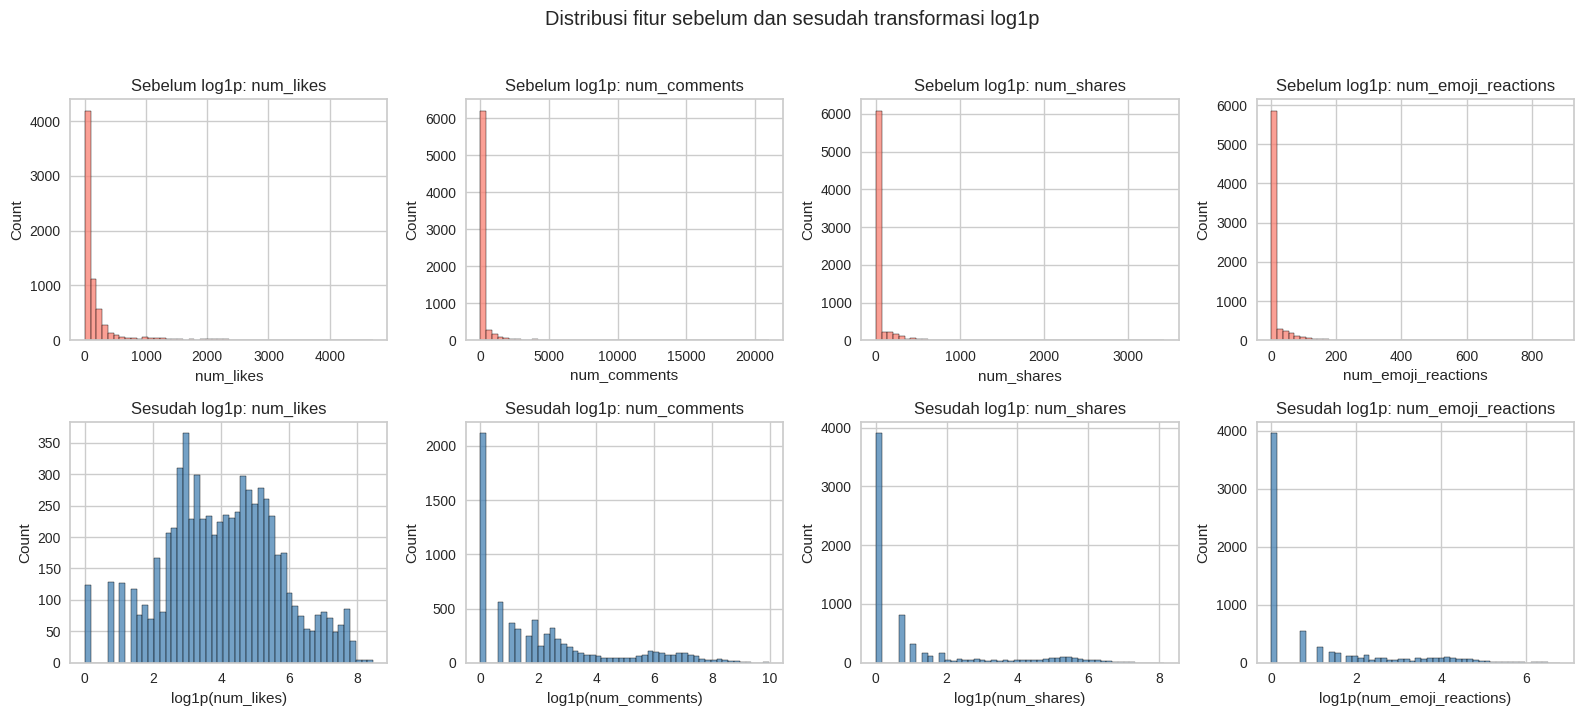

Skewness sebelum log1p:


,skewness
num_likes,3.932518
num_comments,8.994234
num_shares,7.072010
num_emoji_reactions,6.972702


Skewness sesudah log1p:


,skewness
num_likes,-0.012163
num_comments,1.047660
num_shares,1.529132
num_emoji_reactions,1.311034


In [10]:
# Fitur hitungan pada dataset ini sangat miring (skewed). Terapkan transformasi log1p pada fitur yang dipilih.
# Tampilkan distribusi fitur sebelum dan sesudah transformasi untuk melihat perbedaannya.
X_log = np.log1p(X_raw)

fig, axes = plt.subplots(2, len(fitur_cluster), figsize=(16, 7))
for j, kolom in enumerate(fitur_cluster):
    sns.histplot(X_raw[kolom], bins=50, ax=axes[0, j], color="salmon")
    axes[0, j].set_title(f"Sebelum log1p: {kolom}")
    axes[0, j].set_xlabel(kolom)
    sns.histplot(X_log[kolom], bins=50, ax=axes[1, j], color="steelblue")
    axes[1, j].set_title(f"Sesudah log1p: {kolom}")
    axes[1, j].set_xlabel(f"log1p({kolom})")
fig.suptitle("Distribusi fitur sebelum dan sesudah transformasi log1p", y=1.02)
plt.tight_layout()
plt.show()

print("Skewness sebelum log1p:")
display(X_raw.skew().to_frame("skewness"))
print("Skewness sesudah log1p:")
display(X_log.skew().to_frame("skewness"))


In [11]:
# Lakukan feature scaling (misalnya StandardScaler) pada fitur hasil transformasi log dan simpan hasilnya (X_log_scaled).
# Simpan juga versi lain untuk keperluan perbandingan pada bagian 3.1:
# - X_raw: fitur mentah tanpa transformasi dan tanpa scaling
# - X_raw_scaled: fitur mentah dengan scaling saja
scaler_log = StandardScaler()
X_log_scaled = scaler_log.fit_transform(X_log)

scaler_raw = StandardScaler()
X_raw_scaled = scaler_raw.fit_transform(X_raw)

print("Shape X_raw:", X_raw.shape)
print("Shape X_raw_scaled:", X_raw_scaled.shape)
print("Shape X_log_scaled:", X_log_scaled.shape)
print("\nRata-rata X_log_scaled (mendekati 0):", np.round(X_log_scaled.mean(axis=0), 6))
print("Standar deviasi X_log_scaled (mendekati 1):", np.round(X_log_scaled.std(axis=0), 6))


Shape X_raw: (6996, 4)
Shape X_raw_scaled: (6996, 4)
Shape X_log_scaled: (6996, 4)

Rata-rata X_log_scaled (mendekati 0): [-0. -0.  0. -0.]
Standar deviasi X_log_scaled (mendekati 1): [1. 1. 1. 1.]


# 3. Eksperimen K-Means

## 3.1 Pengaruh Transformasi Log dan Feature Scaling pada K-Means

K-Means mengelompokkan data dengan meminimalkan jarak antara titik dan centroid cluster. Pada bagian ini kalian akan mengamati bagaimana transformasi log dan scaling memengaruhi hasil clustering.

In [12]:
# Latih K-Means dengan jumlah cluster yang sama (misalnya k=3) pada tiga versi data:
# (1) X_raw (mentah tanpa scaling), (2) X_raw_scaled (mentah dengan scaling), dan (3) X_log_scaled (log dan scaling).
# Gunakan random_state dan n_init yang sama agar perbandingan adil.
RANDOM_STATE = 42
N_INIT = 10
K_PERBANDINGAN = 3

varian_data = {
    "X_raw (tanpa transformasi & scaling)": X_raw,
    "X_raw_scaled (scaling saja)": X_raw_scaled,
    "X_log_scaled (log1p + scaling)": X_log_scaled,
}

model_31 = {}
label_31 = {}
for nama, data in varian_data.items():
    model = KMeans(
        n_clusters=K_PERBANDINGAN, random_state=RANDOM_STATE, n_init=N_INIT
    )
    label_31[nama] = model.fit_predict(data)
    model_31[nama] = model
    print(f"{nama}: inertia = {model.inertia_:.2f}")


X_raw (tanpa transformasi & scaling): inertia = 2368964516.60
X_raw_scaled (scaling saja): inertia = 11817.41
X_log_scaled (log1p + scaling): inertia = 6779.84


In [13]:
# Bandingkan ketiga hasil tersebut: jumlah anggota tiap cluster dan Silhouette Score.
# Hitung Silhouette ketiganya pada ruang yang sama (misalnya X_log_scaled) agar perbandingannya adil.
# Amati fitur mana yang mendominasi varians pada data tanpa scaling, dan apakah ada cluster yang sangat kecil atau sangat besar.
baris_perbandingan = []
for nama, labels in label_31.items():
    ukuran = pd.Series(labels).value_counts().sort_index()
    baris = {
        "Data": nama,
        "Silhouette (dinilai pada X_log_scaled)": silhouette_score(
            X_log_scaled, labels
        ),
    }
    for c in range(K_PERBANDINGAN):
        baris[f"Cluster {c}"] = int(ukuran.get(c, 0))
    baris["Cluster terkecil"] = int(ukuran.min())
    baris["Cluster terbesar"] = int(ukuran.max())
    baris_perbandingan.append(baris)

tabel_31 = pd.DataFrame(baris_perbandingan).set_index("Data")
display(tabel_31.round(4))

print("Varians tiap fitur mentah:")
varians_raw = X_raw.var().sort_values(ascending=False)
display(varians_raw.to_frame("varians"))
print("Proporsi varians tiap fitur mentah:")
display((varians_raw / varians_raw.sum()).to_frame("proporsi_varians"))


,Silhouette (dinilai pada X_log_scaled),Cluster 0,Cluster 1,Cluster 2,Cluster terkecil,Cluster terbesar
Data,,,,,,
X_raw (tanpa transformasi & scaling),0.2731,6392,137,467,137,6392
X_raw_scaled (scaling saja),0.2533,373,6277,346,346,6277
X_log_scaled (log1p + scaling),0.4638,1131,2258,3607,1131,3607


Varians tiap fitur mentah:


,varians
num_comments,797310.065490
num_likes,193268.441395
num_shares,17443.167343
num_emoji_reactions,2299.572319


Proporsi varians tiap fitur mentah:


,proporsi_varians
num_comments,0.789165
num_likes,0.191294
num_shares,0.017265
num_emoji_reactions,0.002276


## 3.2 Menentukan Jumlah Cluster dengan Elbow Method

Elbow Method memplot nilai inertia (Within-Cluster Sum of Squares) terhadap jumlah cluster k. Titik "siku" pada grafik menunjukkan nilai k setelah mana penambahan cluster tidak lagi memberikan penurunan inertia yang berarti.

In [14]:
# Latih K-Means pada X_log_scaled untuk rentang k tertentu (misalnya k = 2 sampai 10).
# Simpan nilai inertia untuk setiap k.
rentang_k = range(2, 11)
inertia_per_k = {}

for k in rentang_k:
    model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=N_INIT)
    model.fit(X_log_scaled)
    inertia_per_k[k] = model.inertia_

tabel_inertia = pd.DataFrame({
    "k": list(inertia_per_k.keys()),
    "inertia": list(inertia_per_k.values()),
})
tabel_inertia["penurunan_%"] = tabel_inertia["inertia"].pct_change().mul(-100)
display(tabel_inertia.round(2))


,k,inertia,penurunan_%
0,2,11586.90,NaN
1,3,6779.84,41.49
2,4,5678.25,16.25
3,5,4739.96,16.52
4,6,4220.28,10.96
5,7,3772.10,10.62
6,8,3418.57,9.37
7,9,3116.43,8.84
8,10,2899.05,6.98


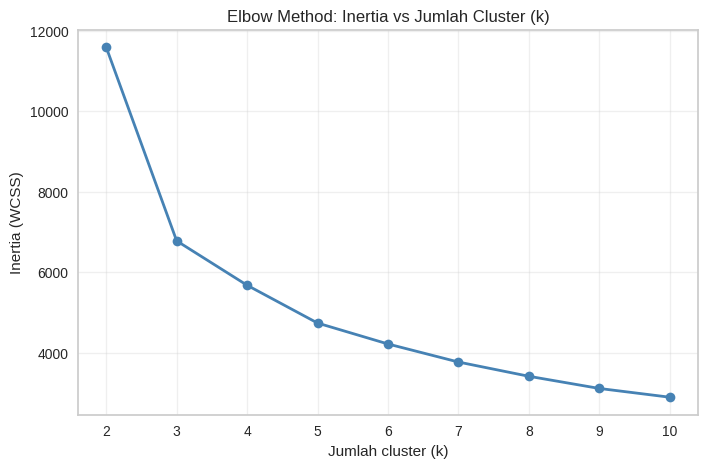

Library kneed tidak tersedia; elbow ditentukan dari penurunan inertia.
 k  inertia  penurunan_%
 2 11586.90          NaN
 3  6779.84        41.49
 4  5678.25        16.25
 5  4739.96        16.52
 6  4220.28        10.96
 7  3772.10        10.62
 8  3418.57         9.37
 9  3116.43         8.84
10  2899.05         6.98
Perkiraan elbow (penurunan inertia > 20%): 3


In [15]:
# Plot grafik Elbow (k vs inertia).
# Amati pada nilai k berapa terbentuk "siku".
# (Opsional) Gunakan library kneed (KneeLocator) untuk mendeteksi elbow secara otomatis, lalu bandingkan dengan pengamatan kalian.
plt.figure(figsize=(8, 5))
plt.plot(
    list(inertia_per_k.keys()), list(inertia_per_k.values()),
    marker="o", linewidth=2, color="steelblue",
)
plt.title("Elbow Method: Inertia vs Jumlah Cluster (k)")
plt.xlabel("Jumlah cluster (k)")
plt.ylabel("Inertia (WCSS)")
plt.xticks(list(inertia_per_k.keys()))
plt.grid(alpha=0.3)
plt.show()

elbow_k = None
try:
    from kneed import KneeLocator

    knee = KneeLocator(
        list(inertia_per_k.keys()), list(inertia_per_k.values()),
        curve="convex", direction="decreasing",
    )
    elbow_k = knee.elbow
    print("Elbow terdeteksi otomatis oleh kneed:", elbow_k)
except ImportError:
    print("Library kneed tidak tersedia; elbow ditentukan dari penurunan inertia.")
    print(tabel_inertia.round(2).to_string(index=False))
    penurunan = tabel_inertia.set_index("k")["penurunan_%"].abs()
    kandidat = penurunan[penurunan > 20].index
    elbow_k = int(kandidat.max()) if len(kandidat) else None
    print("Perkiraan elbow (penurunan inertia > 20%):", elbow_k)


## 3.3 Menentukan Jumlah Cluster dengan Silhouette Score

Silhouette Score mengukur seberapa mirip sebuah titik dengan clusternya sendiri dibandingkan dengan cluster lain. Nilainya berkisar dari -1 sampai 1, semakin tinggi semakin baik.

In [16]:
# Hitung Silhouette Score untuk setiap nilai k pada rentang yang sama dengan Elbow Method.
# Simpan hasilnya dalam list atau dictionary agar mudah diplot.
silhouette_per_k = {}
for k in rentang_k:
    model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=N_INIT)
    labels = model.fit_predict(X_log_scaled)
    silhouette_per_k[k] = silhouette_score(X_log_scaled, labels)

tabel_silhouette = pd.DataFrame({
    "k": list(silhouette_per_k.keys()),
    "silhouette_score": list(silhouette_per_k.values()),
})
display(tabel_silhouette.round(4))


,k,silhouette_score
0,2,0.5899
1,3,0.4638
2,4,0.3372
3,5,0.3586
4,6,0.3469
5,7,0.3367
6,8,0.3154
7,9,0.3293
8,10,0.3160


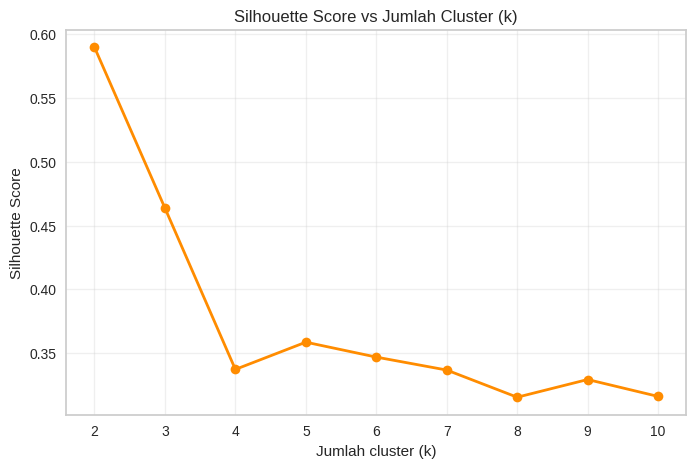

k dengan Silhouette Score tertinggi: 2 (0.5899)
Perkiraan elbow dari Elbow Method: 3
k final yang dipilih untuk K-Means: 3


In [17]:
# Plot grafik Silhouette Score terhadap k.
# Tentukan nilai k terbaik dengan mempertimbangkan hasil Elbow Method dan Silhouette Score, lalu jelaskan alasannya pada cell markdown di bawah.
plt.figure(figsize=(8, 5))
plt.plot(
    list(silhouette_per_k.keys()), list(silhouette_per_k.values()),
    marker="o", linewidth=2, color="darkorange",
)
plt.title("Silhouette Score vs Jumlah Cluster (k)")
plt.xlabel("Jumlah cluster (k)")
plt.ylabel("Silhouette Score")
plt.xticks(list(silhouette_per_k.keys()))
plt.grid(alpha=0.3)
plt.show()

k_silhouette_terbaik = max(silhouette_per_k, key=silhouette_per_k.get)
print(
    f"k dengan Silhouette Score tertinggi: {k_silhouette_terbaik} "
    f"({silhouette_per_k[k_silhouette_terbaik]:.4f})"
)
print(f"Perkiraan elbow dari Elbow Method: {elbow_k}")

# Memilih k=3: elbow terbentuk di k=3 dan Silhouette Score masih relatif tinggi,
# sedangkan k=2 terlalu kasar untuk membedakan pola engagement.
k_final = 3
print(f"k final yang dipilih untuk K-Means: {k_final}")


**Pilihan k untuk K-Means:** **k = 3**.

Alasan:
- Elbow Method menunjukkan penurunan inertia terbesar dari k=2 ke k=3, yaitu 41,49% (11.586,90 → 6.779,84). Setelah k=3, penurunan hanya 16,25% (k=4) dan terus mengecil, sehingga "siku" berada di k=3.
- Silhouette Score tertinggi secara global ada di k=2 (0,5899), tetapi k=2 hanya memisahkan data menjadi dua kelompok yang sangat kasar. Pada k=3 silhouette masih relatif tinggi (0,4638) dan merupakan nilai terbaik setelah k=2; k=4 justru turun ke 0,3372.
- k=3 juga menghasilkan tiga segmen engagement yang seimbang dan mudah diinterpretasikan: engagement rendah, engagement berbasis like, dan engagement berbasis komentar/share (video).


## 3.4 Model K-Means Final

In [18]:
# Latih model K-Means final dengan nilai k terbaik yang kalian pilih pada X_log_scaled.
# Simpan label cluster hasil prediksi untuk keperluan evaluasi.
kmeans_final = KMeans(
    n_clusters=k_final, random_state=RANDOM_STATE, n_init=N_INIT
)
kmeans_labels = kmeans_final.fit_predict(X_log_scaled)
df["cluster_kmeans"] = kmeans_labels

print("Inertia model final:", round(kmeans_final.inertia_, 2))
print(
    "Silhouette Score model final:",
    round(silhouette_score(X_log_scaled, kmeans_labels), 4),
)
print("Jumlah anggota tiap cluster:")
display(
    pd.Series(kmeans_labels, name="cluster")
    .value_counts()
    .sort_index()
    .to_frame("jumlah")
)


Inertia model final: 6779.84


Silhouette Score model final: 0.4638
Jumlah anggota tiap cluster:


,jumlah
cluster,
0,1131
1,2258
2,3607


In [19]:
# Buat profil setiap cluster pada data ASLI (sebelum transformasi log dan scaling): tampilkan median (dan rata-rata) tiap fitur per cluster beserta jumlah anggotanya.
# Gunakan median karena distribusi fitur sangat miring.
# Ini membantu menginterpretasikan karakteristik tiap cluster.
profil_median_kmeans = (
    df.groupby("cluster_kmeans")[fitur_cluster].median().round(2).add_prefix("median_")
)
profil_mean_kmeans = (
    df.groupby("cluster_kmeans")[fitur_cluster].mean().round(2).add_prefix("mean_")
)
profil_kmeans = pd.concat(
    [
        df.groupby("cluster_kmeans").size().rename("jumlah_anggota"),
        profil_median_kmeans,
        profil_mean_kmeans,
    ],
    axis=1,
)
display(profil_kmeans)


,jumlah_anggota,median_num_likes,median_num_comments,median_num_shares,median_num_emoji_reactions,mean_num_likes,mean_num_comments,mean_num_shares,mean_num_emoji_reactions
cluster_kmeans,,,,,,,,,
0,1131,170.0,722.0,178.0,57.0,304.50,1335.37,238.04,83.25
1,2258,206.0,11.0,1.0,2.0,462.73,26.89,4.69,4.57
2,3607,18.0,0.0,0.0,0.0,22.23,2.11,0.55,0.23


# 4. Eksperimen Hierarchical Clustering

## 4.1 Dendrogram

Hierarchical Clustering (Agglomerative) memulai dengan setiap titik sebagai cluster tersendiri, lalu menggabungkan dua cluster terdekat secara berulang hingga tersisa satu cluster. Dendrogram memvisualisasikan proses penggabungan tersebut.

In [20]:
# Hitung linkage matrix (scipy.cluster.hierarchy.linkage) dengan metode ward pada X_log_scaled.
# Dataset berisi sekitar 7.000 baris sehingga proses ini masih ringan dan tidak perlu dilakukan sampling.
Z_ward = linkage(X_log_scaled, method="ward")
print("Shape linkage matrix:", Z_ward.shape)
display(
    pd.DataFrame(
        Z_ward[-5:],
        columns=["cluster_1", "cluster_2", "jarak", "jumlah_anggota"],
    ).round(3)
)


Shape linkage matrix: (6995, 4)


,cluster_1,cluster_2,jarak,jumlah_anggota
0,13973.0,13983.0,37.539,3034.0
1,13978.0,13984.0,42.310,1615.0
2,13982.0,13987.0,48.409,2922.0
3,13986.0,13988.0,103.701,5956.0
4,13985.0,13989.0,175.130,6996.0


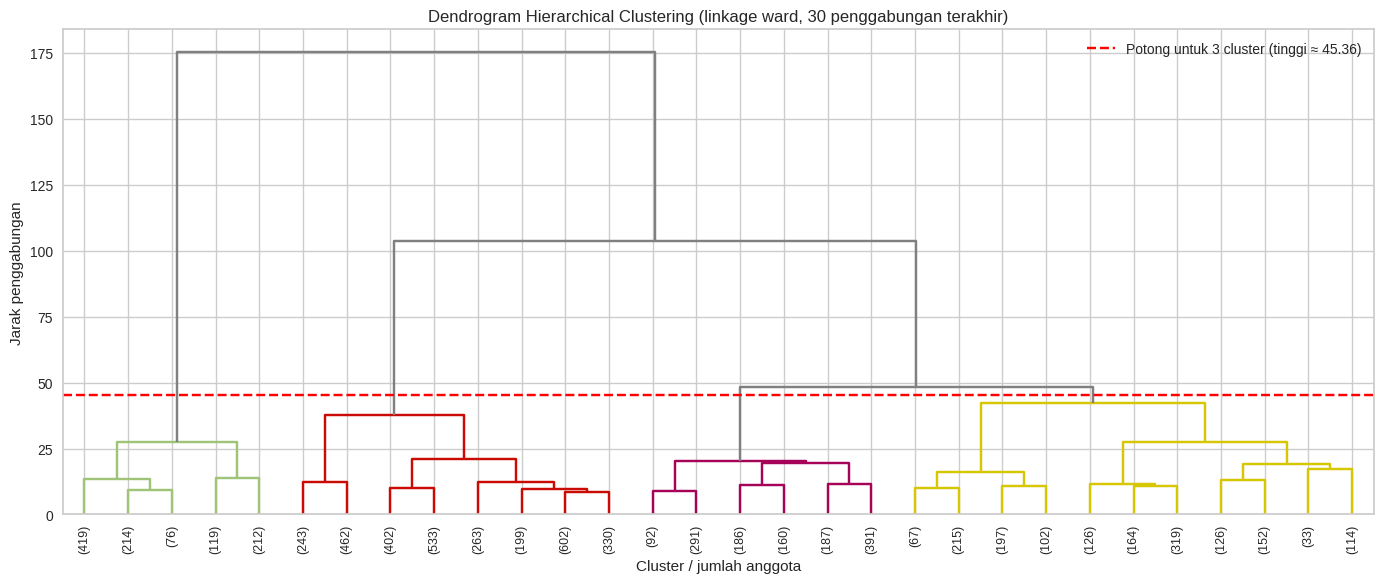

Ketinggian potong untuk 3 cluster: 45.3593


In [21]:
# Tampilkan dendrogram dari linkage matrix di atas.
# Batasi tampilan agar mudah dibaca (misalnya truncate_mode='lastp' atau p=30).
# Amati pada ketinggian berapa sebaiknya dendrogram dipotong untuk menentukan jumlah cluster.
tinggi_potong = (Z_ward[-4, 2] + Z_ward[-3, 2]) / 2

plt.figure(figsize=(14, 6))
dendrogram(
    Z_ward,
    truncate_mode="lastp",
    p=30,
    show_leaf_counts=True,
    leaf_rotation=90,
    leaf_font_size=9,
    color_threshold=tinggi_potong,
    above_threshold_color="grey",
)
plt.axhline(
    y=tinggi_potong,
    color="red",
    linestyle="--",
    label=f"Potong untuk {k_final} cluster (tinggi ≈ {tinggi_potong:.2f})",
)
plt.title("Dendrogram Hierarchical Clustering (linkage ward, 30 penggabungan terakhir)")
plt.xlabel("Cluster / jumlah anggota")
plt.ylabel("Jarak penggabungan")
plt.legend()
plt.tight_layout()
plt.show()
print(f"Ketinggian potong untuk {k_final} cluster: {tinggi_potong:.4f}")


## 4.2 Perbandingan Metode Linkage

Linkage menentukan cara jarak antar cluster dihitung. Pada bagian ini kalian akan membandingkan empat metode linkage: ward, complete, average, dan single.

In [22]:
# Latih AgglomerativeClustering dengan masing-masing linkage (ward, complete, average, single).
# Gunakan jumlah cluster yang sama untuk semua linkage agar perbandingan adil.
metode_linkage = ["ward", "complete", "average", "single"]
model_hc_banding = {}
label_hc_banding = {}

for metode in metode_linkage:
    model = AgglomerativeClustering(n_clusters=k_final, linkage=metode)
    label_hc_banding[metode] = model.fit_predict(X_log_scaled)
    model_hc_banding[metode] = model
    print(f"Linkage {metode}: selesai")


Linkage ward: selesai


Linkage complete: selesai


Linkage average: selesai


Linkage single: selesai


In [23]:
# Hitung Silhouette Score untuk setiap linkage dan tampilkan jumlah anggota tiap cluster.
# Sajikan dalam satu tabel perbandingan.
# Amati apakah ada linkage yang menghasilkan cluster sangat tidak seimbang (misalnya satu cluster sangat besar dan lainnya hanya beberapa titik).
baris_linkage = []
for metode, labels in label_hc_banding.items():
    ukuran = pd.Series(labels).value_counts().sort_index()
    baris = {
        "Linkage": metode,
        "Silhouette Score": silhouette_score(X_log_scaled, labels),
        "Davies-Bouldin": davies_bouldin_score(X_log_scaled, labels),
        "Calinski-Harabasz": calinski_harabasz_score(X_log_scaled, labels),
        "Rasio cluster terbesar/terkecil": ukuran.max() / ukuran.min(),
    }
    for c in range(k_final):
        baris[f"Cluster {c}"] = int(ukuran.get(c, 0))
    baris_linkage.append(baris)

tabel_linkage = pd.DataFrame(baris_linkage).set_index("Linkage")
display(tabel_linkage.round(4))


,Silhouette Score,Davies-Bouldin,Calinski-Harabasz,Rasio cluster terbesar/terkecil,Cluster 0,Cluster 1,Cluster 2
Linkage,,,,,,,
ward,0.4201,0.8329,9959.1882,2.9173,2922,1040,3034
complete,0.1163,0.7472,2560.5575,12.5543,5775,460,761
average,0.5069,0.5221,4856.5349,164.6857,1197,5764,35
single,0.3139,0.4851,3.4667,6994.0000,6994,1,1


**Pilihan linkage untuk Hierarchical Clustering:** **ward**.

Alasan:
- Pada k=3, linkage ward menghasilkan Silhouette Score 0,4201 dengan ukuran cluster yang seimbang (2.922; 1.040; 3.034; rasio terbesar/terkecil 2,92) serta Calinski-Harabasz tertinggi di antara linkage yang seimbang (9.959,19).
- Linkage average memang memiliki silhouette lebih tinggi (0,5069), tetapi menghasilkan satu cluster sangat kecil berisi 35 anggota (rasio 164,69), sehingga tidak layak untuk segmentasi.
- Linkage complete memiliki cluster yang tidak seimbang (5.775; 460; 761; rasio 12,55) dan silhouette rendah (0,1163).
- Linkage single mengalami degenerasi: 6.994 anggota masuk satu cluster dan dua anggota menjadi singleton, sehingga tidak berguna.
- Ward juga konsisten dengan linkage yang dipakai pada dendrogram dan meminimalkan varians di dalam cluster.


## 4.3 Model Hierarchical Clustering Final

In [24]:
# Latih model AgglomerativeClustering final dengan linkage terbaik dan jumlah cluster yang sama dengan K-Means final.
# Simpan label cluster hasil prediksi untuk keperluan evaluasi.
linkage_final = "ward"
hc_final = AgglomerativeClustering(n_clusters=k_final, linkage=linkage_final)
hc_labels = hc_final.fit_predict(X_log_scaled)
df["cluster_hc"] = hc_labels

print("Linkage final:", linkage_final)
print(
    "Silhouette Score model final:",
    round(silhouette_score(X_log_scaled, hc_labels), 4),
)
print("Jumlah anggota tiap cluster:")
display(
    pd.Series(hc_labels, name="cluster")
    .value_counts()
    .sort_index()
    .to_frame("jumlah")
)


Linkage final: ward


Silhouette Score model final: 0.4201
Jumlah anggota tiap cluster:


,jumlah
cluster,
0,2922
1,1040
2,3034


In [25]:
# Buat profil setiap cluster pada data ASLI (sebelum transformasi log dan scaling): tampilkan median (dan rata-rata) tiap fitur per cluster beserta jumlah anggotanya.
profil_median_hc = (
    df.groupby("cluster_hc")[fitur_cluster].median().round(2).add_prefix("median_")
)
profil_mean_hc = (
    df.groupby("cluster_hc")[fitur_cluster].mean().round(2).add_prefix("mean_")
)
profil_hc = pd.concat(
    [
        df.groupby("cluster_hc").size().rename("jumlah_anggota"),
        profil_median_hc,
        profil_mean_hc,
    ],
    axis=1,
)
display(profil_hc)


,jumlah_anggota,median_num_likes,median_num_comments,median_num_shares,median_num_emoji_reactions,mean_num_likes,mean_num_comments,mean_num_shares,mean_num_emoji_reactions
cluster_hc,,,,,,,,,
0,2922,150.0,9.0,1.0,1.0,386.75,29.40,5.27,4.48
1,1040,168.0,815.5,193.5,60.5,277.53,1430.19,255.40,88.24
2,3034,14.0,0.0,0.0,0.0,16.71,1.76,0.25,0.15


# 5. Evaluasi Model

In [26]:
# Hitung metrik evaluasi INTERNAL untuk K-Means dan Hierarchical Clustering:
# Silhouette Score (semakin tinggi semakin baik), Davies-Bouldin Index (semakin rendah semakin baik), dan Calinski-Harabasz Score (semakin tinggi semakin baik).
# Sajikan dalam satu tabel perbandingan.
metrik_evaluasi = pd.DataFrame({
    "Model": ["K-Means", f"Hierarchical (linkage {linkage_final})"],
    "Silhouette Score": [
        silhouette_score(X_log_scaled, kmeans_labels),
        silhouette_score(X_log_scaled, hc_labels),
    ],
    "Davies-Bouldin Index": [
        davies_bouldin_score(X_log_scaled, kmeans_labels),
        davies_bouldin_score(X_log_scaled, hc_labels),
    ],
    "Calinski-Harabasz Score": [
        calinski_harabasz_score(X_log_scaled, kmeans_labels),
        calinski_harabasz_score(X_log_scaled, hc_labels),
    ],
}).set_index("Model")
display(metrik_evaluasi.round(4))


,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Score
Model,,,
K-Means,0.4638,0.8302,10935.4612
Hierarchical (linkage ward),0.4201,0.8329,9959.1882


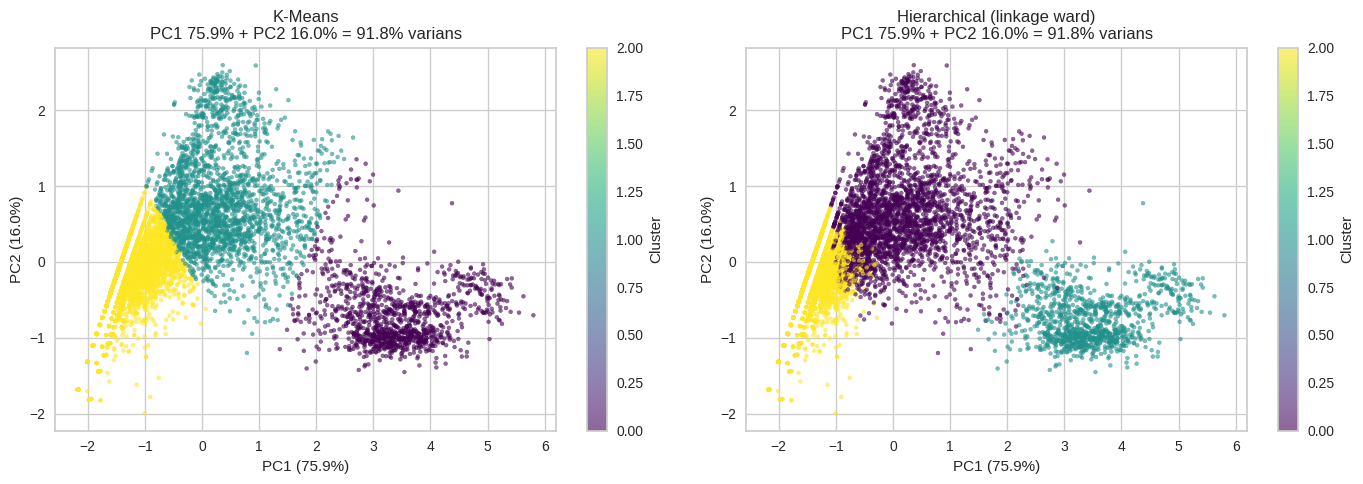

Varians yang dijelaskan PC1 dan PC2: 75.87% + 15.95% = 91.82%


In [27]:
# Lakukan PCA ke 2 komponen pada X_log_scaled.
# Tampilkan scatter plot hasil clustering K-Means dan Hierarchical Clustering dalam satu baris subplot, diwarnai berdasarkan label cluster.
# Tampilkan juga persentase varians yang dijelaskan oleh kedua komponen PCA.
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_log_scaled)
varians = pca.explained_variance_ratio_ * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, labels, judul in [
    (axes[0], kmeans_labels, "K-Means"),
    (axes[1], hc_labels, f"Hierarchical (linkage {linkage_final})"),
]:
    scatter = ax.scatter(
        X_pca[:, 0], X_pca[:, 1], c=labels, cmap="viridis", s=8, alpha=0.6
    )
    ax.set_title(
        f"{judul}\nPC1 {varians[0]:.1f}% + PC2 {varians[1]:.1f}% "
        f"= {varians.sum():.1f}% varians"
    )
    ax.set_xlabel(f"PC1 ({varians[0]:.1f}%)")
    ax.set_ylabel(f"PC2 ({varians[1]:.1f}%)")
    plt.colorbar(scatter, ax=ax, label="Cluster")
plt.tight_layout()
plt.show()
print(
    f"Varians yang dijelaskan PC1 dan PC2: {varians[0]:.2f}% + "
    f"{varians[1]:.2f}% = {varians.sum():.2f}%"
)


Komposisi status_type per cluster K-Means (%):


status_type,link,photo,status,video
cluster_kmeans,,,,
0,0.00,4.60,0.97,94.43
1,1.11,65.32,10.41,23.16
2,1.05,75.27,3.13,20.54


Komposisi status_type per cluster Hierarchical (ward) (%):


status_type,link,photo,status,video
cluster_hc,,,,
0,1.27,65.33,10.10,23.31
1,0.00,0.87,0.00,99.13
2,0.86,76.60,2.11,20.44


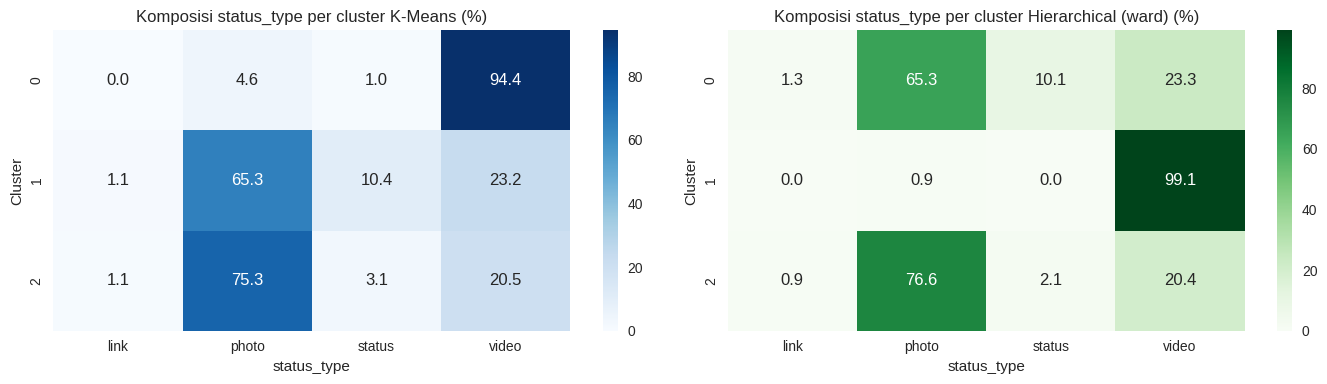

In [28]:
# Tampilkan komposisi status_type pada tiap cluster (crosstab dalam persen) untuk K-Means dan Hierarchical Clustering dalam bentuk heatmap.
# Susun keduanya dalam satu baris subplot.
# Ini hanya untuk membantu interpretasi cluster, bukan sebagai label asli.
komposisi_kmeans = (
    pd.crosstab(df["cluster_kmeans"], df["status_type"], normalize="index") * 100
)
komposisi_hc = (
    pd.crosstab(df["cluster_hc"], df["status_type"], normalize="index") * 100
)

print("Komposisi status_type per cluster K-Means (%):")
display(komposisi_kmeans.round(2))
print(f"Komposisi status_type per cluster Hierarchical ({linkage_final}) (%):")
display(komposisi_hc.round(2))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.heatmap(komposisi_kmeans, annot=True, fmt=".1f", cmap="Blues", ax=axes[0])
axes[0].set_title("Komposisi status_type per cluster K-Means (%)")
axes[0].set_xlabel("status_type")
axes[0].set_ylabel("Cluster")
sns.heatmap(komposisi_hc, annot=True, fmt=".1f", cmap="Greens", ax=axes[1])
axes[1].set_title(
    f"Komposisi status_type per cluster Hierarchical ({linkage_final}) (%)"
)
axes[1].set_xlabel("status_type")
axes[1].set_ylabel("Cluster")
plt.tight_layout()
plt.show()


# 6. Analisis

### Jelaskan secara detail hasil analisis yang didapatkan dari eksperimen yang telah dilakukan.

Beberapa hal yang perlu dibahas:
- Jelaskan pengaruh transformasi log dan feature scaling pada K-Means berdasarkan hasil pada bagian 3.1. Mengapa keduanya penting pada algoritma berbasis jarak, terutama untuk data yang sangat miring dan mengandung outlier ekstrem?
- Bagaimana kalian menangani kolom yang redundan atau banyak bernilai nol (misalnya reaksi emoji)? Jelaskan alasan pemilihan fitur kalian.
- Berapa jumlah cluster optimal menurut Elbow Method dan Silhouette Score? Apakah keduanya menghasilkan kesimpulan yang sama? Jika berbeda, mana yang kalian pilih dan mengapa?
- Bandingkan hasil keempat metode linkage pada Hierarchical Clustering. Linkage mana yang paling baik dan mengapa? Bagaimana karakteristik cluster yang dihasilkan oleh single linkage?
- Bandingkan performa K-Means vs Hierarchical Clustering berdasarkan metrik internal dan visualisasi PCA. Apakah hasilnya berbeda signifikan? Menurut kalian, kenapa demikian?
- Bagaimana karakteristik tiap cluster berdasarkan profil median fitur dan komposisi status_type? Beri nama atau julukan yang menggambarkan tiap cluster.
- Apa kelebihan dan kekurangan masing-masing metode (misalnya dari sisi kebutuhan menentukan k di awal, bentuk cluster, dan kebutuhan waktu serta memori)?

Pastikan analisis didasari oleh hasil eksperimen sendiri yang telah dilakukan, bukan hasil orang lain.

---

**Jawaban:**

**1. Pengaruh transformasi log dan feature scaling pada K-Means (bagian 3.1)**

Dengan k=3 dan `random_state`/`n_init` yang sama, ketiga versi data menghasilkan kualitas yang sangat berbeda:

| Data | Silhouette (dinilai pada X_log_scaled) | Ukuran cluster |
|---|---|---|
| X_raw | 0,2731 | 6.392 / 137 / 467 |
| X_raw_scaled | 0,2533 | 373 / 6.277 / 346 |
| X_log_scaled | **0,4638** | 1.131 / 2.258 / 3.607 |

Pada data mentah, `num_comments` mendominasi 78,9% total varians, sedangkan `num_likes` 19,1%, `num_shares` 1,7%, dan `num_emoji_reactions` hanya 0,2%. Akibatnya jarak antar titik hampir sepenuhnya ditentukan oleh komentar: satu cluster berisi 6.392 dari 6.996 titik, sementara dua cluster lain hanya 137 dan 467 titik. Tanpa scaling, fitur dengan skala besar (komentar maksimum 20.990) menenggelamkan fitur lain.

Scaling saja (`X_raw_scaled`) belum cukup. `StandardScaler` memakai mean dan standar deviasi yang sangat terdistorsi oleh outlier ekstrem, sehingga distribusi tetap sangat miring dan satu cluster masih menyerap 6.277 titik (89,7%). Silhouette justru sedikit turun menjadi 0,2533.

Transformasi `log1p` lebih dulu, baru `StandardScaler`, menurunkan skewness secara drastis: `num_comments` dari 8,99 menjadi 1,05; `num_shares` dari 7,07 menjadi 1,53; `num_emoji_reactions` dari 6,97 menjadi 1,31; dan `num_likes` dari 3,93 menjadi mendekati 0 (-0,01). Setelah itu scaling menyeimbangkan skala antar fitur. Hasilnya cluster jauh lebih seimbang (1.131 / 2.258 / 3.607) dan Silhouette naik menjadi 0,4638. Jadi `log1p` penting untuk meredam outlier dan skewness, sedangkan scaling penting agar tidak ada fitur yang mendominasi jarak.

**2. Penanganan kolom redundan dan banyak nol**

Empat kolom `Column1`–`Column4` seluruhnya kosong dan dihapus. `num_reactions` tidak dipakai karena merupakan penjumlahan `num_likes` dan seluruh reaksi emoji; korelasinya dengan `num_likes` mencapai 0,995. Jika keduanya dipakai, informasi yang sama dihitung dua kali dan jarak menjadi bias. `num_likes` dipertahankan sebagai representasi reaksi utama.

Reaksi emoji individual sangat sparse: `num_hahas` 83,9% nol, `num_angrys` 94,0% nol, `num_wows` 75,3% nol, `num_sads` 91,4% nol, dan `num_loves` 60,0% nol. Jika kelimanya dipakai terpisah, jarak antar titik didominasi oleh banyak nilai nol dan fitur-fitur tersebut hampir tidak membedakan cluster. Karena itu kelimanya digabung menjadi `num_emoji_reactions`. Fitur gabungan ini tetap memiliki 56,5% nilai nol, tetapi jauh lebih informatif daripada lima fitur terpisah dan berkorelasi kuat dengan `num_shares` (0,805).

Fitur final: `num_likes`, `num_comments`, `num_shares`, dan `num_emoji_reactions`.

**3. Jumlah cluster optimal: Elbow vs Silhouette**

Elbow Method pada `X_log_scaled` menunjukkan inertia: k=2 11.586,90; k=3 6.779,84; k=4 5.678,25; k=5 4.739,96; dan seterusnya. Penurunan terbesar terjadi dari k=2 ke k=3 (41,49%), lalu melandai menjadi 16,25% pada k=4. Siku yang jelas berada di **k=3**.

Silhouette Score tertinggi secara global ada di **k=2 (0,5899)**, kemudian k=3 (0,4638), k=4 (0,3372), k=5 (0,3586), dan seterusnya. Jadi kedua metode tidak sepenuhnya sepakat: silhouette cenderung memilih k terkecil karena semakin sedikit cluster, semakin mudah memisahkan kelompok besar. Elbow menunjukkan bahwa tambahan cluster setelah k=3 tidak memberi perbaikan proporsional.

Saya memilih **k=3** karena: (a) elbow jelas di k=3; (b) silhouette k=3 masih cukup tinggi dan merupakan nilai terbaik kedua; (c) k=2 terlalu kasar dan hanya membagi data menjadi "engagement tinggi vs rendah" tanpa membedakan pola like, komentar, dan share; (d) k=3 menghasilkan tiga segmen yang seimbang dan interpretatif. Kualitas clustering tidak hanya dilihat dari silhouette tertinggi, tetapi juga dari kegunaan dan kestabilan segmen.

**4. Perbandingan linkage**

Pada k=3, hasil keempat linkage:

| Linkage | Silhouette | Davies-Bouldin | Calinski-Harabasz | Ukuran cluster | Rasio maks/min |
|---|---|---|---|---|---|
| ward | 0,4201 | 0,8329 | 9.959,19 | 2.922 / 1.040 / 3.034 | 2,92 |
| complete | 0,1163 | 0,7472 | 2.560,56 | 5.775 / 460 / 761 | 12,55 |
| average | 0,5069 | 0,5221 | 4.856,53 | 1.197 / 5.764 / 35 | 164,69 |
| single | 0,3139 | 0,4851 | 3,47 | 6.994 / 1 / 1 | 6.994 |

- **Ward** paling seimbang: rasio cluster terbesar/terkecil hanya 2,92 dan Calinski-Harabasz tertinggi (9.959,19). Silhouette 0,4201 sedikit di bawah average, tetapi Davies-Bouldin-nya baik (0,8329).
- **Complete** memiliki silhouette rendah (0,1163) dan cluster tidak seimbang (5.775 vs 460 vs 761).
- **Average** memiliki silhouette tertinggi (0,5069), tetapi satu cluster hanya berisi 35 titik. Nilai silhouette bisa tinggi justru karena cluster kecil sangat terpisah, sehingga tidak cocok untuk segmentasi.
- **Single** mengalami chaining: 6.994 titik bergabung dalam satu cluster dan dua titik menjadi singleton. Ini karakteristik single linkage yang rentan terhadap efek berantai dan outlier. Calinski-Harabasz-nya sangat rendah (3,47).

Linkage terbaik untuk tugas ini adalah **ward**, karena menghasilkan cluster seimbang, metrik internal kompetitif, dan interpretasi yang stabil. Average/single tidak dipilih karena degenerasi ukuran cluster.

**5. K-Means vs Hierarchical Clustering**

| Metrik | K-Means (k=3) | Hierarchical ward (k=3) |
|---|---|---|
| Silhouette Score | **0,4638** | 0,4201 |
| Davies-Bouldin Index | **0,8302** | 0,8329 |
| Calinski-Harabasz Score | **10.935,46** | 9.959,19 |

K-Means sedikit lebih unggul pada ketiga metrik, tetapi selisihnya tidak besar (silhouette +0,0437; Davies-Bouldin praktis sama). Secara struktur, kedua metode menemukan segmen yang sama: satu cluster video dengan komentar/share sangat tinggi, satu cluster likes moderat, dan satu cluster engagement rendah. PCA 2 komponen menjelaskan 91,82% varians (PC1 75,87%, PC2 15,95%), dan scatter plot kedua metode memperlihatkan pemisahan kelompok yang serupa.

Perbedaan kecil ini wajar karena K-Means mengoptimalkan jarak ke centroid secara langsung, sedangkan ward mengoptimalkan kenaikan varians pada setiap penggabungan. Pada data yang sudah log-transformed dan scaled, struktur kelompoknya cukup jelas, sehingga kedua algoritma konvergen ke partisi yang mirip. K-Means lebih unggul tipis karena centroid dapat bergerak bebas, sementara hierarchical membatasi penggabungan secara hierarkis.

**6. Karakteristik dan penamaan cluster**

Profil median pada data asli (K-Means, k=3):

| Cluster | n | Likes | Komentar | Shares | Emoji | Dominasi status_type | Usulan nama |
|---|---|---|---|---|---|---|---|
| 0 | 1.131 | 170 | 722 | 178 | 57 | 94,4% video | **Video viral & diskusi tinggi** |
| 1 | 2.258 | 206 | 11 | 1 | 2 | 65,3% foto; 23,2% video | **Posting populer berbasis like** |
| 2 | 3.607 | 18 | 0 | 0 | 0 | 75,3% foto; 20,5% video | **Posting sepi / engagement rendah** |

Hierarchical ward menghasilkan tiga segmen yang sama dengan urutan label berbeda: cluster 1 (1.040 anggota, 99,1% video) adalah **video viral & diskusi tinggi**; cluster 0 (2.922 anggota) adalah **posting populer berbasis like**; cluster 2 (3.034 anggota) adalah **posting sepi**. Komposisi status_type K-Means dan ward sangat mirip, menandakan hasil yang konsisten.

Interpretasi:
- **Video viral & diskusi tinggi** memiliki komentar dan share jauh di atas cluster lain (median 722 komentar dan 178 share). Ini menunjukkan video memicu percakapan dan penyebaran, bukan sekadar like.
- **Posting populer berbasis like** memiliki likes tinggi (median 206) tetapi komentar dan share rendah. Engagement bersifat pasif: penonton menyukai tanpa berdiskusi.
- **Posting sepi** didominasi nilai nol pada semua fitur (median likes 18, komentar/share/emoji 0). Sebagian besar posting tidak mendapat engagement berarti.

`status_type` hanya dipakai untuk interpretasi ini, bukan sebagai fitur clustering, sesuai ketentuan tugas.

**7. Kelebihan dan kekurangan masing-masing metode**

| Aspek | K-Means | Hierarchical (ward) |
|---|---|---|
| Penentuan k | Harus ditentukan sebelum training | Bisa dieksplorasi lewat dendrogram, tetapi jumlah cluster final tetap harus dipilih |
| Bentuk cluster | Cenderung bulat/konveks dan berukuran relatif seimbang | Dapat menangkap struktur hierarkis; ward cenderung kompak dan seimbang |
| Waktu & memori | Cepat dan ringan, cocok untuk data besar; O(n·k·d·iterasi) | Linkage ward O(n²) waktu dan memori; pada 7.000 baris masih ringan, tetapi tidak praktis untuk jutaan baris |
| Sensitivitas | Sensitif terhadap inisialisasi dan outlier; perlu `n_init` dan scaling | Sensitif terhadap linkage dan outlier; single linkage rentan chaining |
| Interpretasi | Perlu profil cluster; tidak memberi hubungan antarcluster | Dendrogram memberi gambaran penggabungan dan kemiripan antarcluster |
| Hasil eksperimen | Silhouette 0,4638; DB 0,8302; CH 10.935,46 | Silhouette 0,4201; DB 0,8329; CH 9.959,19 |

K-Means lebih cocok untuk segmentasi cepat pada data besar dan menghasilkan metrik sedikit lebih baik. Hierarchical ward lebih cocok untuk eksplorasi struktur dan jumlah cluster, serta memberikan dendrogram yang informatif. Untuk data ini, keduanya menghasilkan segmentasi yang konsisten; pemilihan akhir dapat mempertimbangkan kebutuhan (kecepatan vs eksplorasi hierarki).


# 7. Kesimpulan dan Saran

### Berikan kesimpulan dari eksperimen yang telah dilakukan.

Saran dapat berupa rekomendasi untuk eksperimen selanjutnya (misalnya melakukan clustering terpisah untuk periode sebelum dan sesudah tahun 2016, memanfaatkan fitur waktu seperti jam atau hari posting, mencoba algoritma clustering lain seperti DBSCAN atau Gaussian Mixture Model, melakukan reduksi dimensi sebelum clustering, atau mencoba variasi hyperparameter lain seperti n_init dan init pada K-Means), perbaikan model, atau hal-hal lain yang relevan dengan tugas ini.

---

**Kesimpulan:**

1. Dataset `Live.csv` terdiri dari 7.050 baris dan 16 kolom; empat kolom kosong dihapus dan 54 baris duplikat (identik tanpa `status_id`) dibuang, menyisakan 6.996 baris tanpa missing value. Fitur engagement sangat miring dan banyak bernilai nol, dengan outlier ekstrem berupa posting viral (misalnya 20.990 komentar).
2. Pemilihan fitur menghasilkan empat fitur: `num_likes`, `num_comments`, `num_shares`, dan `num_emoji_reactions` (gabungan lima reaksi emoji). `num_reactions` dihilangkan karena redundan dengan `num_likes` (korelasi 0,995), sedangkan reaksi emoji digabung karena sangat sparse.
3. Transformasi `log1p` + `StandardScaler` sangat penting. Tanpa keduanya, `num_comments` mendominasi 78,9% varians dan K-Means menghasilkan satu cluster raksasa (6.392 dari 6.996 titik; silhouette 0,2731). Dengan `log1p` + scaling, silhouette naik menjadi 0,4638 dan ukuran cluster jauh lebih seimbang (1.131 / 2.258 / 3.607).
4. Elbow Method menunjukkan k=3 (penurunan inertia 41,49% dari k=2 ke k=3), sedangkan Silhouette Score tertinggi di k=2 (0,5899). k=3 dipilih karena memberi trade-off terbaik antara kualitas metrik dan interpretasi: tiga segmen engagement yang jelas (video viral, populer berbasis like, dan sepi).
5. Pada Hierarchical Clustering, linkage ward dipilih karena paling seimbang (rasio 2,92) dengan silhouette 0,4201 dan Calinski-Harabasz 9.959,19. Average dan single menghasilkan cluster degenerat (35 titik dan dua singleton), sedangkan complete menghasilkan cluster tidak seimbang dengan silhouette rendah.
6. K-Means sedikit lebih unggul dari hierarchical ward (silhouette 0,4638 vs 0,4201; Davies-Bouldin 0,8302 vs 0,8329; Calinski-Harabasz 10.935,46 vs 9.959,19), tetapi keduanya menemukan struktur cluster yang sama. PCA 2 komponen menjelaskan 91,82% varians dan memperlihatkan pemisahan kelompok yang serupa.
7. Tiga segmen yang terbentuk: **video viral & diskusi tinggi** (94,4% video; median 722 komentar dan 178 share), **posting populer berbasis like** (median 206 likes tetapi komentar/share rendah), dan **posting sepi/engagement rendah** (median 18 likes; komentar, share, dan emoji nol). `status_type` hanya dipakai untuk interpretasi, bukan fitur clustering.
8. K-Means unggul dalam kecepatan dan skalabilitas, sedangkan hierarchical ward unggul dalam eksplorasi struktur melalui dendrogram. Untuk segmentasi operasional pada data besar, K-Means lebih praktis; untuk analisis eksploratif dan penentuan jumlah cluster, hierarchical ward lebih informatif.

**Saran:**

- Lakukan clustering terpisah untuk periode sebelum dan sesudah 2016 karena fitur reaksi emoji baru muncul pada 2016; pola engagement sebelum 2016 tidak sebanding.
- Manfaatkan fitur waktu tambahan seperti jam, hari, dan bulan posting untuk melihat pola engagement berdasarkan waktu.
- Coba algoritma lain seperti DBSCAN (untuk mendeteksi outlier/posting viral), Gaussian Mixture Model (cluster berbasis probabilitas), atau K-Medoids (lebih tahan outlier).
- Lakukan reduksi dimensi (PCA) sebelum clustering atau bandingkan dengan UMAP/t-SNE untuk visualisasi, serta evaluasi stabilitas cluster dengan beberapa `random_state`.
- Coba variasi hyperparameter K-Means (`n_init`, `init="k-means++"` vs random, `max_iter`) dan jumlah cluster k=2–5 untuk melihat sensitivitas.
- Pertimbangkan fitur turunan seperti rasio komentar/likes, share/likes, atau engagement per hari sejak posting untuk menangkap intensitas engagement, bukan hanya volume.
- Lakukan validasi eksternal jika tersedia label jenis konten atau data penjualan untuk memastikan cluster bermakna secara bisnis.
